# Industry Project: A Production-Grade ML Prediction API (Production-Style)

> **Who is this notebook for?** Someone who has seen a "hello world" FastAPI app and wants to know what a
> **real** ML API at a company looks like: one that other teams depend on, that runs 24/7, and that must never
> take the checkout page down with it. Every step is explained in plain English, and almost every line of code has a comment.
> You do **not** need to start a server: we test everything inside the notebook with FastAPI's `TestClient`.

---

### How this notebook is different from the other notebooks in `12_FastAPI/`

| `01`-`03` notebooks | This notebook |
|---|---|
| Show each FastAPI feature on its own (routes, Pydantic, JWT, middleware, lifespan, Prometheus) | Combines them into **one** service the way a team would ship it |
| Iris model saved next to the notebook | Model + **metadata** saved to a versioned artifact folder (a temp dir here) |
| Endpoints are tried by hand | A **test suite** (happy path, bad input, auth, model crash, model missing) runs in-process with `TestClient` |
| `print()` for status | **Structured JSON logs** with a **request ID** on every line |
| No numbers about speed | A small **load test** that measures p50 / p95 / p99 latency against an SLO |
| Docs are "there at /docs" | We **read the OpenAPI schema** and use it as a contract test |

---

### The business problem

You work at an online shop. When a customer clicks **"Pay"**, the checkout service must decide in a few
milliseconds whether the order looks like **payment fraud**. The data-science team has a model; your job is to
put it behind an API that the checkout team can call.

The checkout team's requirements (this is what a real "API contract" conversation sounds like):

| Requirement | Why |
|---|---|
| **p95 latency < 50 ms** inside the service | Checkout has a 300 ms total budget; fraud scoring gets a slice of it |
| **Never return a stack trace**, always a clear JSON error with a request ID | They log the request ID and send it to you when something breaks |
| **Reject bad input with a 422** that says which field is wrong | A silent wrong prediction is worse than a loud error |
| **Versioned URL** (`/v1/...`) | They can't redeploy every time you change something |
| **Health + readiness endpoints** | Kubernetes / the load balancer must know when an instance can take traffic |
| **A batch endpoint** | The risk team re-scores yesterday's orders every night (thousands at once) |
| **Only known callers** may use it (API key) | Fraud scores are sensitive; unknown callers are rejected |

Success = checkout can integrate against the documented contract, and every failure mode returns a
predictable, debuggable answer.

---

### Table of Contents
1. Setup: imports and one central settings object
2. Train and save the model artifact (what the data-science team hands over)
3. The API contract: Pydantic request / response schemas
4. The model service: load once, predict many times
5. Structured logging with request IDs
6. Security: a simple API-key check
7. Errors: one consistent JSON error format
8. Routers, versioning and the lifespan: assembling the app
9. First calls and what the logs look like
10. The test suite (runs without a server)
11. A small load test: latency percentiles vs. the SLO
12. Peek at the OpenAPI schema (and use it as a contract test)
13. From notebook to a real project (layout + run commands)
14. Summary, exercises and resources

---
## 1. Setup: imports and one central settings object

Production services read their configuration from **environment variables** (the [twelve-factor app](https://12factor.net/config) rule): the same code runs in dev, staging and production, only the env vars differ. Here a small frozen `dataclass` reads them with safe defaults. Big projects often use `pydantic-settings` (`BaseSettings`) for this, which does the same thing with type validation.

> **Note:** we import `warnings` and silence warnings *before* importing `fastapi.testclient`, because the
> installed Starlette version prints a deprecation notice about its `httpx` dependency on import. It does not affect anything here.

In [1]:
# ---- Standard library ----
import warnings
warnings.filterwarnings("ignore")      # keep beginner output clean (must run before the imports below)

import json                            # read/write model metadata
import logging                         # structured logs instead of print()
import os                              # read configuration from environment variables
import secrets                         # constant-time string comparison for API keys
import sys                             # log handler writes to stdout
import tempfile                        # temporary folder for the model artifact (never write into the repo)
import time                            # measure latency
import uuid                            # generate request IDs
from contextlib import asynccontextmanager   # FastAPI "lifespan" = code that runs at startup / shutdown
from contextvars import ContextVar     # a "per-request global" for the request ID
from dataclasses import dataclass, field
from datetime import datetime, timezone
from pathlib import Path
from typing import Literal

# ---- Third-party ----
import fastapi
import joblib                          # save / load scikit-learn pipelines
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydantic
import sklearn
from fastapi import APIRouter, Depends, FastAPI, HTTPException, Request
from fastapi.exceptions import RequestValidationError
from fastapi.responses import JSONResponse
from fastapi.security import APIKeyHeader
from fastapi.testclient import TestClient            # calls the app in-process: no server, no network
from pydantic import BaseModel, ConfigDict, Field, field_validator
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from starlette.exceptions import HTTPException as StarletteHTTPException   # also covers 404 / 405

SEED = 42
np.random.seed(SEED)
MAX_BATCH_SIZE = 500                   # biggest batch one request may send (protects memory and latency)
MODEL_NAME = "checkout_fraud"
MODEL_VERSION = "1.0.0"


@dataclass(frozen=True)                # frozen = settings cannot be changed by accident at runtime
class Settings:
    app_name: str = "fraud-scoring-api"
    environment: str = "dev"           # dev / staging / prod
    model_dir: Path = Path("models/checkout_fraud/1.0.0")    # overwritten below with a temp dir
    # API key -> name of the calling service. In production these come from a secret manager, NEVER from code.
    api_keys: dict = field(default_factory=lambda: {"demo-checkout-key": "checkout-service",
                                                    "demo-risk-key": "risk-batch-job"})


def load_settings(model_dir: Path) -> Settings:
    """Build Settings from environment variables, falling back to safe demo defaults."""
    raw_keys = os.environ.get("FRAUD_API_KEYS")          # e.g. "key1:checkout-service,key2:risk-job"
    keys = dict(pair.split(":", 1) for pair in raw_keys.split(",")) if raw_keys else Settings().api_keys
    return Settings(environment=os.environ.get("APP_ENV", "dev"),
                    model_dir=Path(os.environ.get("MODEL_DIR", model_dir)),
                    api_keys=keys)


print(f"fastapi {fastapi.__version__} | pydantic {pydantic.__version__} | scikit-learn {sklearn.__version__}")

fastapi 0.138.1 | pydantic 2.13.4 | scikit-learn 1.9.0


---
## 2. Train and save the model artifact (what the data-science team hands over)

The API team usually **does not train the model**. They receive an **artifact**: a folder with the fitted pipeline and a `metadata.json` describing it (version, input columns, decision thresholds, offline metrics). We quickly create one here so the notebook is self-contained.

The data is a **simulated** checkout log (in real life: a SQL query over the orders table joined with chargeback labels that arrive weeks later). About 2% of orders are fraud, and the signals overlap a lot with normal orders, like in reality.

In [2]:
def make_checkout_log(n_orders: int = 20_000, seed: int = SEED) -> pd.DataFrame:
    """Simulated orders with a fraud label. Fraud is rare and noisy, as in real life."""
    rng = np.random.default_rng(seed)
    country = rng.choice(["US", "GB", "DE", "FR", "BR", "IN", "NG"], n_orders,
                         p=[0.45, 0.12, 0.10, 0.10, 0.09, 0.09, 0.05])
    payment_method = rng.choice(["card", "paypal", "gift_card", "bank_transfer"], n_orders,
                                p=[0.62, 0.25, 0.05, 0.08])
    account_age_days = rng.exponential(400, n_orders).clip(0, 3650).round().astype(int)
    orders_last_30d = rng.poisson(2, n_orders)
    amount = rng.lognormal(3.8, 0.9, n_orders).round(2)              # median order ~ $45, long tail
    shipping_matches_billing = rng.random(n_orders) < 0.85
    hour_of_day = rng.integers(0, 24, n_orders)

    # Hidden "true" fraud behaviour + noise (the model has to learn it from examples)
    logit = (-3.0 + 1.0 * np.log(amount / 50)                         # bigger orders are riskier
             - 3.0 * np.log1p(account_age_days) / np.log(365)        # new accounts are much riskier
             + 1.6 * (~shipping_matches_billing)
             + 1.8 * (payment_method == "gift_card")
             + 0.9 * np.isin(country, ["NG", "BR"])
             + 1.0 * (hour_of_day < 6)                                # night-time orders
             + 0.3 * (orders_last_30d > 5)
             + rng.normal(0, 0.7, n_orders))                          # things we cannot observe
    is_fraud = rng.binomial(1, 1 / (1 + np.exp(-logit)))
    return pd.DataFrame({"amount": amount, "account_age_days": account_age_days,
                         "orders_last_30d": orders_last_30d, "country": country,
                         "payment_method": payment_method,
                         "shipping_matches_billing": shipping_matches_billing,
                         "hour_of_day": hour_of_day, "is_fraud": is_fraud})


orders = make_checkout_log()
FEATURES = [c for c in orders.columns if c != "is_fraud"]
X_train, X_val, y_train, y_val = train_test_split(orders[FEATURES], orders["is_fraud"], test_size=0.25,
                                                  stratify=orders["is_fraud"], random_state=SEED)
print(f"{len(orders):,} orders | fraud rate {orders['is_fraud'].mean():.2%}")
orders.head(3)

20,000 orders | fraud rate 2.01%


,amount,account_age_days,orders_last_30d,country,payment_method,shipping_matches_billing,hour_of_day,is_fraud
0,49.57,53,1,BR,paypal,True,22,0
1,21.84,80,1,US,bank_transfer,True,10,0
2,23.09,75,0,BR,card,False,13,0


We compare a **hand-written rule** (what many shops start with) against a **logistic-regression pipeline**. We pick logistic regression on purpose: it is fast (well under a millisecond per row), easy to explain to auditors, and its probabilities are well behaved. Gradient-boosted trees are the other common choice for fraud; see the exercises.

The pipeline contains **all preprocessing** (log-transform, scaling, one-hot encoding with `handle_unknown="ignore"`), so the API can pass raw JSON fields straight in. That is how you avoid *training-serving skew* (the API computing features slightly differently from training).

In [3]:
NUMERIC = ["amount", "account_age_days", "orders_last_30d", "hour_of_day"]
CATEGORICAL = ["country", "payment_method"]
BOOLEAN = ["shipping_matches_billing"]

preprocess = ColumnTransformer([
    ("num", Pipeline([("log", FunctionTransformer(np.log1p)),        # tame long tails ($5 vs $5,000)
                      ("scale", StandardScaler())]), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),     # unseen country -> all zeros, no crash
    ("bool", "passthrough", BOOLEAN),
])
fraud_pipeline = Pipeline([("preprocess", preprocess),
                           ("model", LogisticRegression(max_iter=1000, C=1.0))])
fraud_pipeline.fit(X_train, y_train)

val_proba = fraud_pipeline.predict_proba(X_val)[:, 1]
# The rule: +1 point for "big order from a new account", +1 point for "shipping != billing address"
rule_score = (((X_val["amount"] > 150) & (X_val["account_age_days"] < 60)).astype(float)
              + (~X_val["shipping_matches_billing"]).astype(float))
offline_metrics = {
    "rule_roc_auc": round(roc_auc_score(y_val, rule_score), 3),
    "model_roc_auc": round(roc_auc_score(y_val, val_proba), 3),
    "model_pr_auc": round(average_precision_score(y_val, val_proba), 3),
    "fraud_rate": round(float(y_val.mean()), 4),
}
# Business decision thresholds: send the riskiest 5% to manual review, block the riskiest 0.5%
REVIEW_THRESHOLD = float(np.quantile(val_proba, 0.95))
BLOCK_THRESHOLD = float(np.quantile(val_proba, 0.995))
caught = y_val[val_proba >= REVIEW_THRESHOLD].sum() / y_val.sum()
print(offline_metrics)
print(f"review if p >= {REVIEW_THRESHOLD:.3f}, block if p >= {BLOCK_THRESHOLD:.3f} "
      f"-> the reviewed 5% of orders contain {caught:.0%} of all fraud")

{'rule_roc_auc': 0.692, 'model_roc_auc': 0.849, 'model_pr_auc': 0.201, 'fraud_rate': 0.02}
review if p >= 0.082, block if p >= 0.291 -> the reviewed 5% of orders contain 43% of all fraud


Now we save the **artifact**: the pipeline plus `metadata.json`. In a real project this folder would be `models/checkout_fraud/1.0.0/` in object storage (S3/GCS) or a model registry (MLflow), and the API would be told which version to load through the `MODEL_DIR` environment variable.

In [4]:
ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="fraud_artifact_")) / MODEL_NAME / MODEL_VERSION
ARTIFACT_DIR.mkdir(parents=True)
joblib.dump(fraud_pipeline, ARTIFACT_DIR / "pipeline.joblib")

metadata = {
    "model_name": MODEL_NAME,
    "model_version": MODEL_VERSION,
    "trained_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__,      # load with the same version, or results may differ
    "input_columns": FEATURES,                   # the column order the pipeline expects
    "thresholds": {"review": REVIEW_THRESHOLD, "block": BLOCK_THRESHOLD},
    "offline_metrics": offline_metrics,
}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
SETTINGS = load_settings(ARTIFACT_DIR)
print("artifact:", ARTIFACT_DIR)
print(sorted(p.name for p in ARTIFACT_DIR.iterdir()))

artifact: /tmp/fraud_artifact_rzwko5s1/checkout_fraud/1.0.0
['metadata.json', 'pipeline.joblib']


---
## 3. The API contract: Pydantic request / response schemas

The schemas **are** the contract with the checkout team. FastAPI uses them to:
1. **validate** every request automatically (wrong type, out of range, missing field -> 422 error),
2. **document** the API (they appear in `/docs` and in the OpenAPI JSON),
3. **filter** responses (`response_model` guarantees we never leak extra internal fields).

Industry details worth copying:
- `Field(gt=0, le=50_000)`: ranges that make **business** sense. A $-5 order is a bug upstream, not an input.
- `extra="forbid"`: a typo like `"ammount"` is rejected instead of silently ignored. (Trade-off: clients can't send extra fields. Some teams prefer `"ignore"` for looser coupling. Choose deliberately.)
- `field_validator(mode="before")`: normalise harmless differences (`" us "` -> `"US"`) *before* the length rule is checked.
- `json_schema_extra` examples: the `/docs` page shows a ready-to-try example.
- A **max batch size** so one caller can't send 10 million rows and freeze the service.

In [5]:
EXAMPLE_ORDER = {"order_id": "ord_000123", "amount": 129.99, "account_age_days": 12, "orders_last_30d": 1,
                 "country": "US", "payment_method": "card", "shipping_matches_billing": False, "hour_of_day": 3}


class Order(BaseModel):
    """One checkout order to score. Field ranges are business rules, not just types."""
    model_config = ConfigDict(extra="forbid", json_schema_extra={"examples": [EXAMPLE_ORDER]})

    order_id: str = Field(min_length=1, max_length=64, description="Caller's order ID, echoed back")
    amount: float = Field(gt=0, le=50_000, description="Order total in USD")
    account_age_days: int = Field(ge=0, le=36_500, description="Days since the customer signed up")
    orders_last_30d: int = Field(ge=0, le=1_000)
    country: str = Field(min_length=2, max_length=2, description="ISO-3166 alpha-2 shipping country")
    payment_method: Literal["card", "paypal", "gift_card", "bank_transfer"]
    shipping_matches_billing: bool
    hour_of_day: int = Field(ge=0, le=23, description="Local hour when the order was placed")

    @field_validator("country", mode="before")         # "before" = runs BEFORE the length check
    @classmethod
    def normalise_country(cls, value):
        if isinstance(value, str):
            value = value.strip().upper()                 # " us " -> "US"
            if not value.isalpha():
                raise ValueError("country must be two letters, e.g. 'US'")
        return value


class FraudScore(BaseModel):
    """What we return for one order."""
    order_id: str
    fraud_probability: float = Field(ge=0, le=1)
    decision: Literal["approve", "review", "block"]
    model_version: str


class BatchRequest(BaseModel):
    orders: list[Order] = Field(min_length=1, max_length=MAX_BATCH_SIZE)


class BatchResponse(BaseModel):
    model_version: str
    n_orders: int
    scores: list[FraudScore]


class ErrorResponse(BaseModel):
    """The ONE error shape every endpoint returns, so callers can parse errors generically."""
    error: str
    detail: object
    request_id: str


# The schema already protects us before any model code runs:
try:
    Order(**{**EXAMPLE_ORDER, "amount": -5, "payment_method": "crypto", "ammount": 1})
except pydantic.ValidationError as err:
    for problem in err.errors():
        print(f"{'.'.join(map(str, problem['loc'])):16s} -> {problem['msg']}")

amount           -> Input should be greater than 0
payment_method   -> Input should be 'card', 'paypal', 'gift_card' or 'bank_transfer'
ammount          -> Extra inputs are not permitted


---
## 4. The model service: load once, predict many times

Loading a model from disk can take seconds (big models: minutes). So we load it **once at startup**, keep it in memory, and reuse it for every request. The `FraudModel` class wraps everything model-specific so the web layer stays thin:

- it reads `metadata.json` and **checks the scikit-learn version** (a mismatch is logged loudly),
- `warmup()` runs one prediction at startup, so the *first real customer* doesn't pay the "cold" cost,
- `predict()` takes validated `Order` objects and returns `FraudScore` objects, including the **business decision** (approve / review / block), not just a number.

In [6]:
class FraudModel:
    """Everything model-specific lives here. The API layer only calls .predict()."""

    def __init__(self, model_dir: Path):
        self.metadata = json.loads((Path(model_dir) / "metadata.json").read_text())
        self.pipeline = joblib.load(Path(model_dir) / "pipeline.joblib")
        self.version = self.metadata["model_version"]
        self.columns = self.metadata["input_columns"]
        self.review_t = self.metadata["thresholds"]["review"]
        self.block_t = self.metadata["thresholds"]["block"]
        if self.metadata["sklearn_version"] != sklearn.__version__:
            api_log.warning("sklearn_version_mismatch", extra={"fields": {
                "trained_with": self.metadata["sklearn_version"], "running": sklearn.__version__}})

    def _decision(self, p: float) -> str:
        return "block" if p >= self.block_t else "review" if p >= self.review_t else "approve"

    def predict(self, orders: list[Order]) -> list[FraudScore]:
        frame = pd.DataFrame([o.model_dump(exclude={"order_id"}) for o in orders])[self.columns]
        probabilities = self.pipeline.predict_proba(frame)[:, 1]          # one vectorised call for the batch
        return [FraudScore(order_id=o.order_id, fraud_probability=round(float(p), 4),
                           decision=self._decision(p), model_version=self.version)
                for o, p in zip(orders, probabilities)]

    def warmup(self) -> None:
        self.predict([Order(**EXAMPLE_ORDER)])                            # pay first-call costs at startup

---
## 5. Structured logging with request IDs

When checkout reports *"order ord_77 got a weird answer at 14:03"*, you need to find **that one request** among millions of log lines. Two habits make this possible:

1. **Structured (JSON) logs**: one JSON object per line. Log platforms (Datadog, ELK, CloudWatch, Loki) can then filter by `status=500` or `latency_ms>100` instead of grepping text.
2. **A request ID** on every log line. The caller may send its own `X-Request-ID` header (so IDs match across services); otherwise we generate one. We return it in the response header too.

A `ContextVar` is a "global variable per request": each concurrent request sees its own value, so log lines from parallel requests never get mixed up.

In [7]:
request_id_var: ContextVar[str] = ContextVar("request_id", default="-")   # "-" outside of a request


class JsonFormatter(logging.Formatter):
    """Turn every log record into one JSON line, including the current request ID."""

    def format(self, record: logging.LogRecord) -> str:
        entry = {
            "ts": datetime.fromtimestamp(record.created, timezone.utc).isoformat(timespec="milliseconds"),
            "level": record.levelname,
            "event": record.getMessage(),
            "request_id": request_id_var.get(),
            **getattr(record, "fields", {}),             # extra key/value pairs passed with extra={"fields": ...}
        }
        if record.exc_info:                               # for errors: the exception type (full traceback in real logs)
            entry["error_type"] = record.exc_info[0].__name__
        return json.dumps(entry)


api_log = logging.getLogger("fraud_api")
api_log.handlers.clear()                                  # avoid duplicate handlers when re-running the cell
_handler = logging.StreamHandler(sys.stdout)
_handler.setFormatter(JsonFormatter())
api_log.addHandler(_handler)
api_log.setLevel(logging.INFO)
api_log.propagate = False                                 # don't also print through the root logger


async def request_context_middleware(request: Request, call_next):
    """Runs around EVERY request: assign request ID, time it, log it, and catch crashes."""
    request_id = request.headers.get("X-Request-ID") or uuid.uuid4().hex[:16]
    token = request_id_var.set(request_id)
    start = time.perf_counter()
    try:
        response = await call_next(request)
    except Exception:                                      # a bug or a crashing model: never leak a stack trace
        api_log.exception("unhandled_error", extra={"fields": {"path": request.url.path}})
        response = JSONResponse(status_code=500, content={
            "error": "internal_error",
            "detail": "Unexpected error. Please contact the fraud team and quote the request_id.",
            "request_id": request_id})
    latency_ms = (time.perf_counter() - start) * 1000
    response.headers["X-Request-ID"] = request_id          # caller can log it on their side
    response.headers["X-Process-Time-Ms"] = f"{latency_ms:.2f}"
    api_log.info("request", extra={"fields": {"method": request.method, "path": request.url.path,
                                              "status": response.status_code,
                                              "latency_ms": round(latency_ms, 2)}})
    request_id_var.reset(token)
    return response

---
## 6. Security: a simple API-key check

Real companies put most authentication in front of the service (API gateway, service mesh with mTLS, OAuth2/JWT as in `02_advanced_fastapi.ipynb`). A per-caller **API key** is still very common for internal service-to-service calls, and it is easy to get right:

- read the key from a header (`X-API-Key`) with FastAPI's `APIKeyHeader` (it also shows up in `/docs` as an "Authorize" button),
- compare with `secrets.compare_digest` (constant time, so attackers can't guess a key character by character from response timing),
- map each key to a **caller name** so logs show *who* called,
- keys live in a **secret manager / env var**, never in git (here they are demo values).

FastAPI's **dependency injection** (`Depends`) lets us attach this check to a whole router at once.

In [8]:
api_key_header = APIKeyHeader(name="X-API-Key", auto_error=False)   # auto_error=False: WE decide the error format


def require_api_key(request: Request, api_key: str | None = Depends(api_key_header)) -> str:
    """Return the caller's name, or raise 401. Used as a router-level dependency."""
    known_keys: dict = request.app.state.settings.api_keys
    for key, caller in known_keys.items():
        if api_key is not None and secrets.compare_digest(api_key, key):
            return caller
    api_log.warning("auth_failed", extra={"fields": {"key_present": api_key is not None}})
    raise HTTPException(status_code=401, detail="Missing or invalid API key",
                        headers={"WWW-Authenticate": "ApiKey"})


def get_model(request: Request) -> FraudModel:
    """Give the endpoint the loaded model, or 503 if it is not loaded (yet)."""
    model = getattr(request.app.state, "model", None)
    if model is None:
        raise HTTPException(status_code=503, detail="Model not loaded; try again later")
    return model

---
## 7. Errors: one consistent JSON error format

FastAPI's default errors are fine for humans but inconsistent for machines (`{"detail": ...}` for some, a long list for validation errors). We register **exception handlers** so *every* error looks like `ErrorResponse`: `{"error": ..., "detail": ..., "request_id": ...}`. The checkout team can then write one generic error parser.

| Status | When | Should the caller retry? |
|---|---|---|
| 401 | missing / wrong API key | No, fix the key |
| 404 / 405 | wrong URL or method | No, fix the client |
| 422 | input breaks the contract | No, fix the data |
| 500 | bug on our side | Maybe once; alert us with the request ID |
| 503 | model not loaded / overloaded | Yes, with back-off (another instance may be ready) |

In [9]:
async def http_error_handler(request: Request, exc: StarletteHTTPException) -> JSONResponse:
    names = {401: "unauthorized", 404: "not_found", 405: "method_not_allowed", 503: "service_unavailable"}
    return JSONResponse(status_code=exc.status_code, headers=getattr(exc, "headers", None),
                        content={"error": names.get(exc.status_code, "http_error"),
                                 "detail": exc.detail, "request_id": request_id_var.get()})


async def validation_error_handler(request: Request, exc: RequestValidationError) -> JSONResponse:
    # Turn Pydantic's verbose error list into short "field -> message" pairs a caller can act on
    problems = [{"field": ".".join(str(p) for p in e["loc"] if p != "body"), "message": e["msg"]}
                for e in exc.errors()]
    api_log.info("validation_failed", extra={"fields": {"n_problems": len(problems)}})
    return JSONResponse(status_code=422, content={"error": "validation_error", "detail": problems,
                                                  "request_id": request_id_var.get()})

---
## 8. Routers, versioning and the lifespan: assembling the app

This follows the structure from the official FastAPI guide ["Bigger Applications"](https://fastapi.tiangolo.com/tutorial/bigger-applications/):

- **`health_router`** (no auth): `/health/live` = "the process is running" (liveness), `/health/ready` = "the model is loaded, send me traffic" (readiness). Kubernetes uses them as `livenessProbe` and `readinessProbe` (see `17_Docker/kubernetes/01_kubernetes.ipynb`). They are different on purpose: an instance that is alive but still loading should get **no traffic**, but should **not** be restarted either.
- **`v1_router`** with `prefix="/v1"` and the API-key dependency on the whole router. When the contract must change in a breaking way, you add a `v2_router` next to it and keep `/v1` running until every caller has migrated.
- **Sync `def` endpoints**: model inference is CPU work. FastAPI runs plain `def` endpoints in a thread pool. An `async def` endpoint that does heavy CPU work would **block the event loop** and freeze every other request.
- **`create_app(settings)` factory + `lifespan`**: the model is loaded at startup and released at shutdown. A factory makes testing easy: tests can build an app with a different config (e.g. a broken model folder).

> **Design choice: fail fast or start degraded?** If the model can't be loaded, we keep the process alive but report **not ready** (503). The orchestrator then keeps traffic away and alerts. The alternative (crash on startup) is also common; both are fine as long as it is deliberate and monitored.

In [10]:
health_router = APIRouter(prefix="/health", tags=["health"])


@health_router.get("/live")
def live() -> dict:
    return {"status": "alive"}


@health_router.get("/ready", responses={503: {"model": ErrorResponse}})
def ready(request: Request):
    model = getattr(request.app.state, "model", None)
    if model is None:
        return JSONResponse(status_code=503, content={"error": "not_ready",
                            "detail": request.app.state.load_error, "request_id": request_id_var.get()})
    return {"status": "ready", "model_version": model.version}


COMMON_ERRORS = {401: {"model": ErrorResponse}, 422: {"model": ErrorResponse}, 503: {"model": ErrorResponse}}
v1_router = APIRouter(prefix="/v1", tags=["fraud scoring v1"], dependencies=[Depends(require_api_key)],
                      responses=COMMON_ERRORS)


@v1_router.post("/predict", response_model=FraudScore, summary="Score one order")
def predict_one(order: Order, caller: str = Depends(require_api_key),
                model: FraudModel = Depends(get_model)) -> FraudScore:
    score = model.predict([order])[0]
    api_log.info("scored", extra={"fields": {"caller": caller, "order_id": order.order_id,
                                             "p": score.fraud_probability, "decision": score.decision}})
    return score


@v1_router.post("/predict/batch", response_model=BatchResponse, summary=f"Score up to {MAX_BATCH_SIZE} orders")
def predict_batch(batch: BatchRequest, model: FraudModel = Depends(get_model)) -> BatchResponse:
    scores = model.predict(batch.orders)
    return BatchResponse(model_version=model.version, n_orders=len(scores), scores=scores)


@v1_router.get("/model", summary="Which model is serving?")
def model_info(model: FraudModel = Depends(get_model)) -> dict:
    keep = ["model_name", "model_version", "trained_at_utc", "input_columns", "offline_metrics"]
    return {k: model.metadata[k] for k in keep}       # never expose everything (e.g. internal paths)


def create_app(settings: Settings) -> FastAPI:
    """App factory: build a fresh, fully configured app (production and tests use the same code)."""

    @asynccontextmanager
    async def lifespan(app: FastAPI):
        app.state.model, app.state.load_error = None, None
        try:
            model = FraudModel(settings.model_dir)
            model.warmup()
            app.state.model = model
            api_log.info("model_loaded", extra={"fields": {"version": model.version, "env": settings.environment}})
        except Exception as exc:                          # keep running, but report "not ready"
            app.state.load_error = f"{type(exc).__name__}: {exc}"
            api_log.error("model_load_failed", extra={"fields": {"reason": app.state.load_error}})
        yield                                             # <- the app serves requests while we are paused here
        app.state.model = None                            # shutdown: release resources
        api_log.info("shutdown")

    app = FastAPI(title="Checkout Fraud Scoring API", version=MODEL_VERSION, lifespan=lifespan,
                  description="Scores checkout orders for payment-fraud risk. Owner: fraud-ml team.")
    app.state.settings = settings
    app.middleware("http")(request_context_middleware)
    app.add_exception_handler(StarletteHTTPException, http_error_handler)
    app.add_exception_handler(RequestValidationError, validation_error_handler)
    app.include_router(health_router)
    app.include_router(v1_router)
    return app


app = create_app(SETTINGS)
# List the registered endpoints (read from the generated OpenAPI document, see Section 12)
print([f"{method.upper()} {path}" for path, ops in app.openapi()["paths"].items() for method in ops])

['GET /health/live', 'GET /health/ready', 'POST /v1/predict', 'POST /v1/predict/batch', 'GET /v1/model']


---
## 9. First calls and what the logs look like

`with TestClient(app) as client:` runs the **lifespan** (startup on enter, shutdown on exit), exactly as the [FastAPI testing-events docs](https://fastapi.tiangolo.com/advanced/testing-events/) describe. Requests go straight into the app in the same process: no port, no network.

Watch the JSON log lines: each has the same `request_id` that comes back in the `X-Request-ID` header.

In [11]:
HEADERS = {"X-API-Key": "demo-checkout-key"}

with TestClient(app) as client:                       # startup: model loads + warmup
    print("ready:", client.get("/health/ready").json())
    response = client.post("/v1/predict", json=EXAMPLE_ORDER, headers={**HEADERS, "X-Request-ID": "chk-42"})
    print("status:", response.status_code, "| X-Request-ID:", response.headers["X-Request-ID"])
    print("body  :", response.json())
# leaving the block = shutdown

{"ts": "2026-10-21T12:38:16.426+00:00", "level": "INFO", "event": "model_loaded", "request_id": "-", "version": "1.0.0", "env": "dev"}


{"ts": "2026-10-21T12:38:16.464+00:00", "level": "INFO", "event": "request", "request_id": "14fa94b05c86483c", "method": "GET", "path": "/health/ready", "status": 200, "latency_ms": 22.11}


ready: {'status': 'ready', 'model_version': '1.0.0'}
{"ts": "2026-10-21T12:38:16.560+00:00", "level": "INFO", "event": "scored", "request_id": "chk-42", "caller": "checkout-service", "order_id": "ord_000123", "p": 0.3217, "decision": "block"}


{"ts": "2026-10-21T12:38:16.576+00:00", "level": "INFO", "event": "request", "request_id": "chk-42", "method": "POST", "path": "/v1/predict", "status": 200, "latency_ms": 102.41}


status: 200 | X-Request-ID: chk-42
body  : {'order_id': 'ord_000123', 'fraud_probability': 0.3217, 'decision': 'block', 'model_version': '1.0.0'}
{"ts": "2026-10-21T12:38:16.578+00:00", "level": "INFO", "event": "shutdown", "request_id": "-"}


The example order (new account, $130, 3 a.m., shipping address different from billing) gets a fraud probability of about 0.32, above the block threshold from Section 2 (about 0.29), so the decision is **block**. Notice how much context the logs carry: caller name, order ID, probability, decision, latency, all tied together by `chk-42`.

---
## 10. The test suite (runs without a server)

These are the tests a team would put in `tests/test_api.py` and run with `pytest` on every pull request (CI). Each one checks a **promise from the contract** in the business-problem table. We run them as plain functions here and quiet the INFO logs so the output stays readable.

The most underrated test is `test_api_matches_offline_model`: it checks that the API returns **exactly** the same probability as the pipeline gives offline. If someone later "optimises" the request-to-DataFrame code and changes a column order, this test catches the silent training-serving skew.

In [12]:
api_log.setLevel(logging.WARNING)            # tests: only warnings/errors are printed


def test_health_and_readiness():
    with TestClient(create_app(SETTINGS)) as c:
        assert c.get("/health/live").json() == {"status": "alive"}
        assert c.get("/health/ready").json()["model_version"] == MODEL_VERSION


def test_predict_happy_path_and_request_id():
    with TestClient(create_app(SETTINGS)) as c:
        r = c.post("/v1/predict", json=EXAMPLE_ORDER, headers=HEADERS)
        assert r.status_code == 200 and r.json()["decision"] in {"approve", "review", "block"}
        assert len(r.headers["X-Request-ID"]) == 16        # generated when the caller sends none


def test_api_matches_offline_model():
    with TestClient(create_app(SETTINGS)) as c:
        rows = X_val.head(20).to_dict(orient="records")
        payload = {"orders": [{"order_id": f"o{i}", **row} for i, row in enumerate(rows)]}
        api_p = [s["fraud_probability"] for s in c.post("/v1/predict/batch", json=payload, headers=HEADERS).json()["scores"]]
        offline_p = np.round(fraud_pipeline.predict_proba(X_val.head(20))[:, 1], 4)
        assert np.allclose(api_p, offline_p), "training-serving skew!"


def test_rejects_missing_or_wrong_api_key():
    with TestClient(create_app(SETTINGS)) as c:
        assert c.post("/v1/predict", json=EXAMPLE_ORDER).status_code == 401
        r = c.post("/v1/predict", json=EXAMPLE_ORDER, headers={"X-API-Key": "guess"})
        assert r.status_code == 401 and r.json()["error"] == "unauthorized"


def test_bad_input_gives_readable_422():
    with TestClient(create_app(SETTINGS)) as c:
        bad = {**EXAMPLE_ORDER, "amount": -10, "hour_of_day": 25}
        r = c.post("/v1/predict", json=bad, headers=HEADERS)
        fields = {p["field"] for p in r.json()["detail"]}
        assert r.status_code == 422 and fields == {"amount", "hour_of_day"}, fields


def test_batch_size_limit():
    with TestClient(create_app(SETTINGS)) as c:
        too_big = {"orders": [EXAMPLE_ORDER] * (MAX_BATCH_SIZE + 1)}
        assert c.post("/v1/predict/batch", json=too_big, headers=HEADERS).status_code == 422


def test_unseen_country_does_not_crash():
    with TestClient(create_app(SETTINGS)) as c:
        r = c.post("/v1/predict", json={**EXAMPLE_ORDER, "country": " jp "}, headers=HEADERS)
        assert r.status_code == 200                        # " jp " -> "JP", unknown to the model -> handled


def test_model_crash_returns_clean_500():
    class BrokenModel:                                     # simulates a bug inside the model code
        version = "broken"
        def predict(self, orders):
            raise RuntimeError("feature store timeout")
    with TestClient(create_app(SETTINGS)) as c:
        c.app.state.model = BrokenModel()
        r = c.post("/v1/predict", json=EXAMPLE_ORDER, headers=HEADERS)
        assert r.status_code == 500 and "Traceback" not in r.text and r.json()["request_id"]


def test_missing_model_means_not_ready():
    broken_settings = load_settings(Path(tempfile.mkdtemp()) / "does_not_exist")
    with TestClient(create_app(broken_settings)) as c:
        assert c.get("/health/live").status_code == 200    # alive ...
        assert c.get("/health/ready").status_code == 503   # ... but not ready: no traffic please
        assert c.post("/v1/predict", json=EXAMPLE_ORDER, headers=HEADERS).status_code == 503


TESTS = [test_health_and_readiness, test_predict_happy_path_and_request_id, test_api_matches_offline_model,
         test_rejects_missing_or_wrong_api_key, test_bad_input_gives_readable_422, test_batch_size_limit,
         test_unseen_country_does_not_crash, test_model_crash_returns_clean_500, test_missing_model_means_not_ready]
for test in TESTS:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_health_and_readiness


PASSED  test_predict_happy_path_and_request_id


PASSED  test_api_matches_offline_model
{"ts": "2026-10-21T12:38:17.665+00:00", "level": "WARNING", "event": "auth_failed", "request_id": "8d1ee921a9ce40c8", "key_present": false}


{"ts": "2026-10-21T12:38:17.676+00:00", "level": "WARNING", "event": "auth_failed", "request_id": "097252b44a754d08", "key_present": true}


PASSED  test_rejects_missing_or_wrong_api_key
PASSED  test_bad_input_gives_readable_422


PASSED  test_batch_size_limit


PASSED  test_unseen_country_does_not_crash
{"ts": "2026-10-21T12:38:18.198+00:00", "level": "ERROR", "event": "unhandled_error", "request_id": "113f70ab158a476a", "path": "/v1/predict", "error_type": "RuntimeError"}


PASSED  test_model_crash_returns_clean_500
{"ts": "2026-10-21T12:38:18.208+00:00", "level": "ERROR", "event": "model_load_failed", "request_id": "-", "reason": "FileNotFoundError: [Errno 2] No such file or directory: '/tmp/tmp6ws5yn1j/does_not_exist/metadata.json'"}


PASSED  test_missing_model_means_not_ready


The JSON lines printed between the `PASSED` messages are **expected**: they are the WARNING/ERROR logs written by the failure tests (failed auth, the simulated model crash with `error_type: RuntimeError`, the missing model). In production these lines are what would trigger an alert. Note that the 500 response itself contains no traceback, only the request ID; the details stay in *our* logs.

---
## 11. A small load test: latency percentiles vs. the SLO

Averages hide pain: if 1 in 20 requests takes 400 ms, the average can still look fine while 5% of customers wait. So teams talk about **percentiles**: p50 (typical), p95, p99 (the slow tail). Our SLO: **p95 < 50 ms**.

We send 300 single-order requests and 20 batch requests of 200 orders, one at a time, through `TestClient`, and also time the model step alone (no HTTP) to see where the time goes.

> **Honest caveat:** this measures the app **in-process** (no network, no JSON over a real socket, one request at a time), on a machine shared with other jobs. It is great for catching regressions ("the new version is 3x slower") but it is **not** a capacity test. For that, run the real server (Section 13) and use a load tool such as [Locust](https://docs.locust.io/), k6 or `hey` with many concurrent users.

In [13]:
def percentile_report(latencies_ms: list[float]) -> dict:
    arr = np.asarray(latencies_ms)
    return {"n": len(arr), **{f"p{q}_ms": round(float(np.percentile(arr, q)), 2) for q in (50, 95, 99)},
            "max_ms": round(float(arr.max()), 2)}


sample_rows = X_val.sample(300, random_state=SEED).to_dict(orient="records")
batch_payload = {"orders": [{"order_id": f"b{i}", **row} for i, row in enumerate(sample_rows[:200])]}
profile_model = FraudModel(ARTIFACT_DIR)                           # the same model, called directly (no HTTP)
single_ms, server_ms, model_only_ms, batch_ms = [], [], [], []

with TestClient(create_app(SETTINGS)) as client:
    for i in range(20):                                             # warm-up requests are not measured
        client.post("/v1/predict", json=EXAMPLE_ORDER, headers=HEADERS)
    # We INTERLEAVE the three measurements, so a busy moment on the machine affects all of them equally
    for i, row in enumerate(sample_rows):
        start = time.perf_counter()
        r = client.post("/v1/predict", json={"order_id": f"lt{i}", **row}, headers=HEADERS)
        single_ms.append((time.perf_counter() - start) * 1000)      # client-side: includes TestClient overhead
        server_ms.append(float(r.headers["X-Process-Time-Ms"]))     # server-side: what our middleware measured
        assert r.status_code == 200

        order = Order(order_id=f"p{i}", **row)                      # model only: DataFrame + pipeline, no HTTP
        start = time.perf_counter()
        profile_model.predict([order])
        model_only_ms.append((time.perf_counter() - start) * 1000)

        if i % 15 == 0:                                             # 20 batch requests of 200 orders
            start = time.perf_counter()
            assert client.post("/v1/predict/batch", json=batch_payload, headers=HEADERS).status_code == 200
            batch_ms.append((time.perf_counter() - start) * 1000)

client_side, server_side = percentile_report(single_ms), percentile_report(server_ms)
model_only, batch = percentile_report(model_only_ms), percentile_report(batch_ms)
print("single, client-side :", client_side)
print("single, server-side :", server_side)
print("model only (no HTTP):", model_only, f"-> {model_only['p50_ms'] / server_side['p50_ms']:.0%} of server-side p50")
print("batch of 200        :", batch, f"-> {batch['p50_ms'] / 200:.3f} ms per order at p50, "
      f"{batch['p50_ms'] / server_side['p50_ms']:.1f}x the time of ONE single-order request")
print(f"SLO p95 < 50 ms (server-side): {'PASS' if server_side['p95_ms'] < 50 else 'FAIL'}")

single, client-side : {'n': 300, 'p50_ms': 28.25, 'p95_ms': 68.44, 'p99_ms': 87.6, 'max_ms': 114.54}
single, server-side : {'n': 300, 'p50_ms': 23.66, 'p95_ms': 56.9, 'p99_ms': 76.37, 'max_ms': 97.04}
model only (no HTTP): {'n': 300, 'p50_ms': 17.59, 'p95_ms': 47.01, 'p99_ms': 55.84, 'max_ms': 62.46} -> 74% of server-side p50
batch of 200        : {'n': 20, 'p50_ms': 29.17, 'p95_ms': 88.79, 'p99_ms': 105.15, 'max_ms': 109.24} -> 0.146 ms per order at p50, 1.2x the time of ONE single-order request
SLO p95 < 50 ms (server-side): FAIL


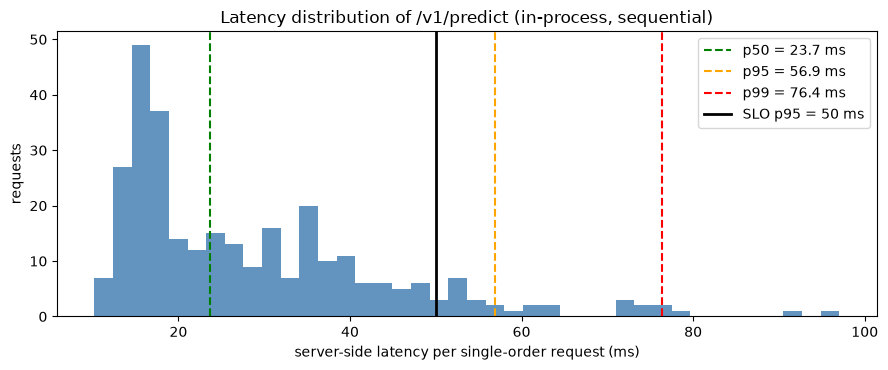

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(server_ms, bins=40, color="steelblue", alpha=0.85)
for name, q, color in [("p50", 50, "green"), ("p95", 95, "orange"), ("p99", 99, "red")]:
    ax.axvline(np.percentile(server_ms, q), color=color, ls="--", label=f"{name} = {np.percentile(server_ms, q):.1f} ms")
ax.axvline(50, color="black", lw=2, label="SLO p95 = 50 ms")
ax.set_xlabel("server-side latency per single-order request (ms)"); ax.set_ylabel("requests")
ax.set_title("Latency distribution of /v1/predict (in-process, sequential)")
ax.legend(); plt.tight_layout(); plt.show()

**How to read this (absolute numbers change from run to run on this shared machine; look at the ratios):**
- **SLO check:** compare the server-side p95 with the 50 ms target in the `PASS`/`FAIL` line. On our development runs it *failed*, with p95 anywhere from about 50 to 90 ms, because this notebook ran on a machine shared with many other heavy jobs. That is a realistic lesson in itself: noisy neighbours are why production services reserve CPU (Kubernetes `requests`/`limits`) and why you benchmark on hardware like production's, not on a laptop or a busy CI runner.
- **Where the time goes:** the "model only" line shows that the model step (building a one-row DataFrame + running the scikit-learn pipeline) is a **large share** of each request; the rest is HTTP handling, JSON, validation, middleware and logging. And the model step is mostly **fixed per-call overhead**, not maths: a batch of 200 orders costs only a small multiple of one single-order request (see the "x the time" number). So the cure is not a bigger machine but (a) **batching / micro-batching** and (b) a leaner single-row path (plain NumPy arrays instead of DataFrames, or exporting the model to ONNX Runtime, see `../05_Deep_Learning/17_industry_model_export_and_inference.ipynb`). Profile first, then optimise.
- **Batching is far cheaper per order**: well under 1 ms per order inside a batch versus tens of milliseconds for a single-order request. That's why nightly re-scoring uses `/v1/predict/batch`.
- The distribution has a **long right tail**: most requests are fast, a few are much slower (garbage collection, the OS scheduling other jobs). That tail is why SLOs use p95/p99, not the mean.
- Client-side numbers are higher than server-side ones because they include TestClient's own work. In production you'd watch both: server-side in your metrics, client-side in the caller's metrics.

---
## 12. Peek at the OpenAPI schema (and use it as a contract test)

FastAPI generates an **OpenAPI** document (`/openapi.json`, rendered at `/docs`) from your code. Other teams generate client code from it, and API gateways import it. Because it is generated, it is always up to date with the code.

A neat industry trick: **snapshot the contract** in a test. If a pull request accidentally makes a new field *required* or removes an endpoint, the test fails before checkout breaks in production.

In [15]:
schema = app.openapi()
print("OpenAPI", schema["openapi"], "|", schema["info"]["title"], schema["info"]["version"])
for path, ops in schema["paths"].items():
    for method, op in ops.items():
        print(f"  {method.upper():5s} {path:22s} {op.get('summary', '')}")

order_schema = schema["components"]["schemas"]["Order"]
print("\nrequired fields:", order_schema["required"])
print("amount rule    :", order_schema["properties"]["amount"])
print("security       :", schema["components"]["securitySchemes"])

OpenAPI 3.1.0 | Checkout Fraud Scoring API 1.0.0
  GET   /health/live           Live
  GET   /health/ready          Ready
  POST  /v1/predict            Score one order
  POST  /v1/predict/batch      Score up to 500 orders
  GET   /v1/model              Which model is serving?

required fields: ['order_id', 'amount', 'account_age_days', 'orders_last_30d', 'country', 'payment_method', 'shipping_matches_billing', 'hour_of_day']
amount rule    : {'type': 'number', 'maximum': 50000.0, 'exclusiveMinimum': 0.0, 'title': 'Amount', 'description': 'Order total in USD'}
security       : {'APIKeyHeader': {'type': 'apiKey', 'in': 'header', 'name': 'X-API-Key'}}


In [16]:
# The contract snapshot. In a real repo this lives in tests/contract/openapi_v1.json and is updated on purpose.
EXPECTED_V1_CONTRACT = {
    "paths": {"/v1/predict", "/v1/predict/batch", "/v1/model", "/health/live", "/health/ready"},
    "order_required": {"order_id", "amount", "account_age_days", "orders_last_30d", "country",
                       "payment_method", "shipping_matches_billing", "hour_of_day"},
}


def test_v1_contract_unchanged():
    s = create_app(SETTINGS).openapi()
    assert EXPECTED_V1_CONTRACT["paths"] <= set(s["paths"]), "an endpoint was removed"
    assert set(s["components"]["schemas"]["Order"]["required"]) == EXPECTED_V1_CONTRACT["order_required"], \
        "required fields changed: that is a BREAKING change -> needs /v2"


test_v1_contract_unchanged()
print("PASSED  test_v1_contract_unchanged")

PASSED  test_v1_contract_unchanged


---
## 13. From notebook to a real project (layout + run commands)

In a repository the same code is split into small modules (following FastAPI's "Bigger Applications" guide):

```
fraud-api/
├── app/
│   ├── main.py            # create_app(), lifespan, middleware, exception handlers
│   ├── settings.py        # Settings / load_settings (env vars)
│   ├── schemas.py         # Order, FraudScore, BatchRequest, ErrorResponse
│   ├── model.py           # FraudModel
│   ├── logging.py         # JsonFormatter, request_id_var
│   └── routers/
│       ├── health.py      # /health/live, /health/ready
│       └── v1.py          # /v1/predict, /v1/predict/batch, /v1/model
├── tests/
│   ├── test_api.py        # the tests from Section 10
│   └── contract/openapi_v1.json
├── requirements.txt       # pinned versions
└── Dockerfile             # see 17_Docker/04_industry_containerizing_an_ml_service.ipynb
```

Commands you would run (not executed in this notebook):

```bash
# development: auto-reload on code changes
MODEL_DIR=models/checkout_fraud/1.0.0 uvicorn app.main:app --reload --port 8000

# production: several worker processes managed by gunicorn (one model copy per worker!)
MODEL_DIR=/models/checkout_fraud/1.0.0 FRAUD_API_KEYS="$KEYS_FROM_SECRET_MANAGER" \
  gunicorn app.main:app -k uvicorn.workers.UvicornWorker -w 2 -b 0.0.0.0:8000 --timeout 30

# call it
curl -s -X POST localhost:8000/v1/predict -H "X-API-Key: $KEY" -H "Content-Type: application/json" \
     -d '{"order_id":"o1","amount":129.99,"account_age_days":12,"orders_last_30d":1,"country":"US",
          "payment_method":"card","shipping_matches_billing":false,"hour_of_day":3}'

# tests in CI
pytest -q tests/
```

> **Memory note:** with `-w 2`, every worker process loads its own copy of the model. A 2 GB model x 4 workers = 8 GB RAM. For big models, use fewer workers per container and scale with more containers.

---
## 14. Summary, exercises and resources

| Practice | What we did | Where it is used in industry |
|---|---|---|
| Config from env vars | `Settings` + `load_settings()` | Same image in dev/staging/prod (12-factor) |
| Model artifact + metadata | `pipeline.joblib` + `metadata.json` with version and thresholds | Model registries (MLflow, SageMaker, Vertex) |
| Load once at startup | `lifespan` + `warmup()` | Every serving stack (BentoML, KServe, TorchServe) |
| Request/response schemas | Pydantic with ranges, `extra="forbid"`, examples | API contracts between teams |
| Versioned routes | `/v1` router, `v2` added side-by-side for breaking changes | Public and internal APIs (Stripe, Google APIs) |
| Liveness vs readiness | `/health/live`, `/health/ready` (503 when model missing) | Kubernetes probes, load-balancer health checks |
| Structured logs + request ID | JSON lines, `ContextVar`, `X-Request-ID` header | Datadog / ELK / CloudWatch, distributed tracing |
| Consistent errors | One `ErrorResponse` shape, no stack traces | Easier client code, safer (no info leaks) |
| API keys | `APIKeyHeader` + `compare_digest` + caller names | Service-to-service auth, usually behind a gateway |
| In-process tests | `TestClient` suite, offline-vs-API skew test | CI on every pull request |
| Latency percentiles | p50/p95/p99 vs SLO, single vs batch | SLOs, performance regression tests |
| Contract snapshot | OpenAPI-based test | Prevents accidental breaking changes |

### Practice exercises
1. Add a `/v2/predict` router whose response also contains the top 3 **reasons** (largest `coef_ * x` contributions of the logistic regression). Keep `/v1` unchanged and confirm `test_v1_contract_unchanged` still passes.
2. Replace `LogisticRegression` with `HistGradientBoostingClassifier`, re-run the load test and compare p95 latency and PR-AUC. Is the accuracy gain worth the latency?
3. Add a simple in-memory **rate limit** per API key (e.g. 100 requests / second) that returns `429 Too Many Requests`, and write a test for it.
4. Use `httpx.AsyncClient(transport=httpx.ASGITransport(app=app))` with `asyncio.gather` to send 50 concurrent requests and compare the latency percentiles with the sequential test.
5. Add Prometheus metrics (request count, latency histogram, decisions per class) using `03_ml_serving_with_fastapi.ipynb` as a guide.

### Resources
- FastAPI docs: [Bigger Applications](https://fastapi.tiangolo.com/tutorial/bigger-applications/), [Testing](https://fastapi.tiangolo.com/tutorial/testing/), [Testing Events / lifespan](https://fastapi.tiangolo.com/advanced/testing-events/), [Lifespan Events](https://fastapi.tiangolo.com/advanced/events/), [Handling Errors](https://fastapi.tiangolo.com/tutorial/handling-errors/)
- [full-stack-fastapi-template](https://github.com/fastapi/full-stack-fastapi-template): the official production reference project
- [The Twelve-Factor App: Config](https://12factor.net/config)
- [Kubernetes: liveness, readiness and startup probes](https://kubernetes.io/docs/concepts/configuration/liveness-readiness-startup-probes/)
- [Google SRE book: Service Level Objectives](https://sre.google/sre-book/service-level-objectives/) (why percentiles, not averages)
- [Locust](https://docs.locust.io/) for real load tests

### Related notebooks in this repo
- `01_fastapi_intro.ipynb`, `02_advanced_fastapi.ipynb` (dependencies, JWT, middleware, lifespan), `03_ml_serving_with_fastapi.ipynb` (Prometheus, HF models)
- `../17_Docker/04_industry_containerizing_an_ml_service.ipynb`: put a service like this in a container
- `../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb`: ship version 2 of the model safely
- `../15_MLOps/07_testing_in_ml/01_testing_ml.ipynb`, `../15_MLOps/06_monitoring/01_monitoring.ipynb`